# BIOT 6900 Module 7 - PDAC knowledge graph
**Shreegowri M Bhojanna | Computational Lab 7 | 30 October 2026**

I used my top 15 PDAC genes from Module 2, the modality priors from Module 3, and three exact DPYD alleles from my Module 5 catalogue. My main question is which drug-target and pathway connections help interpret this shortlist. DPYD is a separate treatment-safety layer because fluorouracil is used in PDAC regimens. It is not labelled as a PDAC driver.

This completes the supplied starter in its original section order. I corrected the evidence mapping, added source/confidence to every edge, used stable identifiers, implemented actual score fusion, and scoped the database operations to this project. All scientific inputs needed for rerunning are bundled under `data/` and uplaoded as zip file to canvas.

No Aura credentials are stored in this notebook.

**Important distinctions:** somatic frequency is not GWAS significance; the protein effect is a difference on the supplied abundance scale, not an established log2 fold-change; a drug-target edge does not establish PDAC efficacy. The six patient records below are synthetic examples, not clinical observations.

## 0 - Install and connect
Updated biot6900_env.yml with required packages and updated the cond environment.
Placed neo4j credentials in my .env file - need to have such neo4j credential file inside "module7" folder before running this notebook.

In [48]:
import importlib.util, subprocess, sys
required = {'neo4j':'neo4j==5.28.2', 'networkx':'networkx==3.4.2',
            'pandas':'pandas>=2.2,<3', 'numpy':'numpy>=1.26,<3',
            'matplotlib':'matplotlib>=3.8,<4', 'scipy':'scipy>=1.12,<2',
            'dotenv':'python-dotenv==1.1.0'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
print('Required packages are available.')

Required packages are available.


In [49]:
from pathlib import Path
import os, json, hashlib, re, math
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import networkx as nx
from IPython.display import display, Markdown
from dotenv import dotenv_values
from neo4j import GraphDatabase

BASE = Path.cwd()
DATA, RESULTS = BASE/'data', BASE/'results'
assert (DATA/'targets_pdac.csv').is_file(), 'Keep module 2 output as input for this excercise.'
RESULTS.mkdir(exist_ok=True)

# Read this specific .env directly, avoiding old environment values.
env_path = (BASE / ".env").resolve()
if not env_path.is_file():
    raise FileNotFoundError(f"Credentials file not found: {env_path}")

cfg = dotenv_values(env_path)
required = ["NEO4J_URI", "NEO4J_USERNAME", "NEO4J_PASSWORD"]
missing = [key for key in required if not cfg.get(key)]
if missing:
    raise ValueError(f"Missing settings in .env: {missing}")

# Close any connection left over from an earlier run.
if "driver" in globals():
    driver.close()

uri = cfg["NEO4J_URI"].strip()
driver = GraphDatabase.driver(
    uri,
    auth=(cfg["NEO4J_USERNAME"], cfg["NEO4J_PASSWORD"]),
    connection_timeout=20,
)

# Retain the database-discovery step that worked.
with driver.session(database="system") as session:
    dbs = session.run("""
        SHOW DATABASES
        YIELD name, currentStatus
        RETURN name, currentStatus
    """).data()

available = sorted({
    row["name"] for row in dbs
    if row["name"] != "system" and row["currentStatus"] == "online"
})

configured_database = (cfg.get("NEO4J_DATABASE") or "").strip()

if configured_database in available:
    database = configured_database
elif len(available) == 1:
    database = available[0]
else:
    display(pd.DataFrame(dbs))
    raise RuntimeError("Cannot identify one usable database from these results.")

PROJECT = "biot6900_module7_pdac_shreegowri"

def run_query(cypher, **params):
    with driver.session(database=database) as session:
        return [record.data() for record in session.run(cypher, **params)]

assert run_query("RETURN 1 AS ok") == [{"ok": 1}]
print("Credentials file:", env_path)
print("Database in file:", repr(configured_database))
print("Database selected:", repr(database))
print("Connected to Neo4j.")

del cfg

Credentials file: C:\Users\shree\Documents\biot6900\module7\.env
Database in file: 'e81b801c'
Database selected: 'e81b801c'
Connected to Neo4j.


## 1 - My disease and evidence
I selected the first 15 genes from module 2 rank. EGFR is a supplementary drug-context gene and DPYD is a supplementary pharmacogenomic gene.

The original `association` values are gene-level somatic mutation frequencies. `rna_p` and `prot_p` are raw Welch-test p-values from the earlier module, not GWAS p-values or FDR values. I leave `gwas_p` missing. I preserve RNA and protein signs. `p_sm` and `p_ab` remain model-derived modality priors from module 3, not observed drug-binding probabilities. I use their maximum as a transparent druggability prior only.
|
Gene identity comes from approved HGNC records, with Ensembl and UniProt cross-checks. Pathway links are a deliberately small selection of explicit Reactome cross-references in reviewed UniProt entries. I did not turn embedding neighbours into experimentally confirmed drug targets.

In [50]:
DISEASE = 'Pancreatic ductal adenocarcinoma (PDAC)'
DISEASE_ID, RELATED_ID = 'DISEASE:PDAC', 'DISEASE:NSCLC'
RELATED = 'Non-small cell lung cancer (NSCLC)'
targets = pd.read_csv(DATA/'targets_pdac.csv') #from module 2
week3 = pd.read_csv(DATA/'targets_pdac_w3.csv') #from module 3
identifiers = pd.read_csv(DATA/'gene_identifiers.csv').fillna('')
pathways = pd.read_csv(DATA/'pathway_memberships.csv')
for frame in (targets, week3, identifiers):
    frame['gene'] = frame['gene'].str.strip().str.upper()
    assert not frame['gene'].duplicated().any()
selected = targets.sort_values('rank', kind='stable').head(15).copy()
selected = selected.merge(week3[['gene','p_sm','p_ab','final','rank']].rename(columns={'rank':'module3_rank','final':'module3_score'}), on='gene', validate='one_to_one')
selected['druggability_prior'] = selected[['p_sm','p_ab']].max(axis=1)
selected['gwas_p'] = np.nan
assert len(selected)==15 and selected[['p_sm','p_ab']].notna().all().all()
assert selected['association'].between(0,1).all()
assert identifiers['hgnc_id'].is_unique and identifiers['ensembl'].is_unique
assert identifiers['ensembl'].str.fullmatch(r'ENSG\d{11}').all()
ID = dict(zip(identifiers.gene, identifiers.hgnc_id))
alias_to_id = {}
ambiguous_aliases = set()
for r in identifiers.to_dict('records'):
    for alias in [r['gene'], r['hgnc_id'], r['ensembl'], *r['aliases'].split('|')]:
        if not alias: continue
        if alias in alias_to_id and alias_to_id[alias] != r['hgnc_id']:
            ambiguous_aliases.add(alias)
        else:
            alias_to_id[alias] = r['hgnc_id']
def canonical_gene(value):
    value = str(value).strip()
    if value in ambiguous_aliases: raise ValueError('Ambiguous gene alias: '+value)
    if value not in alias_to_id: raise ValueError('Unmapped gene identifier: '+value)
    return alias_to_id[value]
assert canonical_gene('HER4') == canonical_gene('ERBB4') == ID['ERBB4']
display(selected[['rank','gene','rna_effect','prot_effect','association','concordant','score','druggability_prior']])
print('Input:', len(targets), 'genes; selected:', len(selected), '; supplementary:', ['EGFR','DPYD'])
print('GWAS values deliberately missing:', selected.gwas_p.isna().sum())
print('Harmonization test: HER4 and ERBB4 map to the same HGNC node.')

,rank,gene,rna_effect,prot_effect,association,concordant,score,druggability_prior
0,1,COL11A1,2.787325,1.448051,0.028571,True,0.984230,0.095740
1,2,MUC5B,2.071322,1.224256,0.042857,True,0.976274,0.544688
2,3,TNS4,4.351478,1.233976,0.021429,True,0.974962,0.214708
3,4,ERBB4,-2.565261,1.328604,0.021429,False,0.972867,0.702312
4,5,PLIN4,-3.068218,-1.197169,0.021429,True,0.972464,0.000369
5,6,MUC16,3.162246,0.922216,0.078571,True,0.971442,0.147820
6,7,FN1,1.826157,1.263289,0.028571,True,0.971223,0.477748
7,8,POSTN,1.743142,1.353190,0.028571,True,0.970965,0.146661
8,9,NOS1,-1.915787,-1.252302,0.021429,True,0.964461,0.209052
9,10,MUC5AC,3.750809,0.814858,0.050000,True,0.961767,0.591514


Input: 2539 genes; selected: 15 ; supplementary: ['EGFR', 'DPYD']
GWAS values deliberately missing: 15
Harmonization test: HER4 and ERBB4 map to the same HGNC node.


### Carrying Module 5 into PDAC
Module 5 was an annotated DPYD variant catalogue, not patient sequencing or tumor variant calls. I reuse its exact alleles without doing new variant calling. This is relevant to PDAC treatment because fluorouracil is part of regimens such as FOLFIRINOX. It does not show that these variants initiate PDAC.

I use GRCh38 plus genomic HGVS as the variant key and retain rsID as an annotation. This matters here: `rs3918290` occurs with both C>T and C>G in the supplied catalogue. The *2A example is **C>T**. I retain the original mixed ClinVar labels and predictions, without reclassifying variants or assigning a patient dose.

In [51]:
module5 = pd.read_csv(DATA/'module5_DPYD.tsv', sep='\t')
EXACT_ALLELES = {
    'chr1:g.97450058C>T': ('rs3918290', 'DPYD *2A', 'NM_000110.4:c.1905+1G>A'),
    'chr1:g.97082391T>A': ('rs67376798', 'DPYD D949V', 'NM_000110.4:c.2846A>T'),
    'chr1:g.97579893G>C': ('rs75017182', 'DPYD intronic allele', 'NM_000110.4:c.1129-5923C>G')
}
VARIANTS = module5[module5.hgvs_g.isin(EXACT_ALLELES)].copy()
assert len(VARIANTS)==3 and VARIANTS.hgvs_g.is_unique
for r in VARIANTS.to_dict('records'):
    assert r['gene']=='DPYD' and r['rsid']==EXACT_ALLELES[r['hgvs_g']][0]
print('All Module 5 DPYD records:', len(module5), '; exact alleles selected:', len(VARIANTS))
print('Rows sharing rs3918290:', module5[module5.rsid.eq('rs3918290')].hgvs_g.tolist())
display(VARIANTS[['hgvs_g','rsid','consequence','clinvar_sig','clinvar_sig_all','cadd_phred','revel','alphamissense']])
VARIANTS.to_csv(RESULTS/'selected_module5_variants.csv',index=False)

All Module 5 DPYD records: 426 ; exact alleles selected: 3
Rows sharing rs3918290: ['chr1:g.97450058C>G', 'chr1:g.97450058C>T']


,hgvs_g,rsid,consequence,clinvar_sig,clinvar_sig_all,cadd_phred,revel,alphamissense
158,chr1:g.97450058C>T,rs3918290,splice_donor_variant,Pathogenic/Likely pathogenic,Pathogenic/Likely pathogenic | Pathogenic | Co...,23.700,NaN,NaN
281,chr1:g.97579893G>C,rs75017182,intron_variant,drug response,drug response | drug response | drug response ...,0.378,NaN,NaN
308,chr1:g.97082391T>A,rs67376798,missense_variant,Conflicting interpretations of pathogenicity,Conflicting interpretations of pathogenicity |...,29.900,0.962,0.2925


### Schema and sources
The disease identifiers `DISEASE:PDAC` and `DISEASE:NSCLC`, drug identifiers and synthetic patient identifiers are local project identifiers; they are not claimed to be ontology accessions. Genes use HGNC, phenotypes use HPO, pathways use Reactome, and variants use GRCh38 plus genomic HGVS.

Every edge has `source`, `source_url`, `confidence`, `evidence_type` and `evidence_note`. Confidence is an explicit curator weight for the stated relationship, not a calibrated probability: 0.60 for observational multiomics association, 0.80 for symptom/context links, 0.85 for curated pathway membership, 0.90 for pharmacology context, 0.95 for drug-label target/indication evidence, and 0.99 for exact variant-to-gene mapping. Synthetic edges have weight 1.0 only to represent the constructed data and are excluded from biological graph analytics.

Related-disease reasoning uses NSCLC, which shares weight loss and fatigue. These common symptoms provide a query bridge but weak mechanistic specificity. Both complete paths and the evidence on each step are exported.

In [52]:
FDA_AFATINIB = 'https://www.accessdata.fda.gov/drugsatfda_docs/label/2022/201292s017lbl.pdf'
FDA_ERLOTINIB = 'https://www.accessdata.fda.gov/drugsatfda_docs/label/2016/021743s025lbl.pdf'
NCI_PDAC = 'https://www.cancer.gov/types/pancreatic/hp/pancreatic-treatment-pdq'
NCI_PDAC_PATIENT = 'https://www.cancer.gov/types/pancreatic/patient/pancreatic-treatment-pdq'
NCI_NSCLC = 'https://www.cancer.gov/types/lung/patient/non-small-cell-lung-treatment-pdq'
UNIPROT_DPYD = 'https://www.uniprot.org/uniprotkb/Q12882/entry'
PHENOTYPES = json.loads((DATA/'hpo_terms.json').read_text())['terms']
PHENO_ID = {x['name']:x['id'] for x in PHENOTYPES}

NODES, EDGES = {}, []
def clean(value):
    if isinstance(value, np.generic): value=value.item()
    if value is None: return None
    if isinstance(value, float) and not math.isfinite(value): return None
    return value
def add_node(node_id, kind, name, **props):
    assert node_id not in NODES, 'Duplicate canonical node: '+node_id
    NODES[node_id] = dict(id=node_id, kind=kind, name=name,
        **{k:clean(v) for k,v in props.items()})
def add_edge(src, rel, dst, *, source, source_url, confidence, evidence_type, evidence_note, **props):
    assert src in NODES and dst in NODES, (src, dst)
    assert re.fullmatch(r'[A-Z_]+', rel)
    key=hashlib.sha256(f'{src}|{rel}|{dst}'.encode()).hexdigest()[:20]
    assert not any(x['edge_id']==key for x in EDGES)
    EDGES.append(dict(edge_id=key,src=src,rel=rel,dst=dst,source=source,source_url=source_url,
        confidence=float(confidence),evidence_type=evidence_type,evidence_note=evidence_note,
        retrieved='2026-10-30',**{k:clean(v) for k,v in props.items()}))

add_node(DISEASE_ID,'disease',DISEASE,id_namespace='local')
add_node(RELATED_ID,'disease',RELATED,id_namespace='local')
selected_lookup=selected.set_index('gene').to_dict('index')
for r in identifiers.to_dict('records'):
    extra=selected_lookup.get(r['gene'],{})
    add_node(r['hgnc_id'],'gene',r['gene'],ensembl=r['ensembl'],uniprot=r['uniprot'],
        aliases=r['aliases'],role='candidate' if extra else 'context',gwas_p=None,
        identifier_source=r['source_url'],
        **{k:v for k,v in extra.items() if k!='gwas_p'})
for row in selected.to_dict('records'):
    add_edge(ID[row['gene']],'ASSOCIATED_WITH',DISEASE_ID,source='Module 2 CPTAC-PDAC gene-level summaries',
        source_url='https://linkedomics.org/data_download/CPTAC-PDAC/',confidence=0.60,
        evidence_type='observational_multiomics',evidence_note='Selected tumor-normal RNA/protein effects and somatic frequency; not causal or GWAS evidence.',
        input_file='data/targets_pdac.csv',rna_p=row['rna_p'],prot_p=row['prot_p'],
        rna_effect=row['rna_effect'],prot_effect=row['prot_effect'],somatic_frequency=row['association'])
for ph in PHENOTYPES:
    add_node(ph['id'],'phenotype',ph['name'],id_namespace='HPO')
    add_edge(DISEASE_ID,'HAS_PHENOTYPE',ph['id'],source='NCI PDQ pancreatic cancer',source_url=NCI_PDAC,
        confidence=0.80,evidence_type='clinical_description',evidence_note='Recognized symptom; not specific to PDAC and not observed in a supplied patient.')
for term in ['Weight loss','Fatigue']:
    add_edge(RELATED_ID,'HAS_PHENOTYPE',PHENO_ID[term],source='NCI PDQ NSCLC',source_url=NCI_NSCLC,
        confidence=0.80,evidence_type='clinical_description',evidence_note='Shared nonspecific clinical feature; not proof of shared drug response.')
for r in pathways[['pathway_id','pathway_name']].drop_duplicates().to_dict('records'):
    add_node(r['pathway_id'],'pathway',r['pathway_name'],id_namespace='Reactome')
for r in pathways.to_dict('records'):
    add_edge(canonical_gene(r['gene']),'PARTICIPATES_IN',r['pathway_id'],source=r['source'],source_url=r['source_url'],
        confidence=r['confidence'],evidence_type='curated_pathway',evidence_note='Reactome cross-reference in reviewed UniProt; membership does not establish activation in PDAC.',pathway_url=r['pathway_url'])

DRUGS = [('DRUG:afatinib','Afatinib'),('DRUG:erlotinib','Erlotinib'),('DRUG:fluorouracil','Fluorouracil')]
for did,name in DRUGS: add_node(did,'drug',name,id_namespace='local')
for did,gene,url,label in [('DRUG:afatinib','ERBB4',FDA_AFATINIB,'GILOTRIF 2022 label section 12.1'),
                           ('DRUG:afatinib','EGFR',FDA_AFATINIB,'GILOTRIF 2022 label section 12.1'),
                           ('DRUG:erlotinib','EGFR',FDA_ERLOTINIB,'TARCEVA 2016 label section 12.1')]:
    add_edge(did,'TARGETS',ID[gene],source=label,source_url=url,confidence=0.95,evidence_type='drug_label_mechanism',
        evidence_note='Biochemical inhibitory target; does not imply efficacy for every tumor containing the gene.')
add_edge(ID['EGFR'],'ASSOCIATED_WITH',DISEASE_ID,source='TARCEVA 2016 label sections 1.2 and 12.1',source_url=FDA_ERLOTINIB,
    confidence=0.80,evidence_type='therapeutic_context',evidence_note='EGFR is the target of erlotinib, used with gemcitabine in advanced pancreatic cancer; not a claim of mutation prevalence or a predictive PDAC biomarker.')
add_edge(ID['EGFR'],'ASSOCIATED_WITH',RELATED_ID,source='GILOTRIF 2022 label section 1.1',source_url=FDA_AFATINIB,
    confidence=0.95,evidence_type='molecular_subgroup',evidence_note='Association refers to the susceptible EGFR-mutated metastatic NSCLC subgroup, not all NSCLC.')
for did,dis,url,note in [
 ('DRUG:afatinib',RELATED_ID,FDA_AFATINIB,'Approved labelled NSCLC settings include non-resistant EGFR-mutated metastatic disease; restrictions apply.'),
 ('DRUG:erlotinib',RELATED_ID,FDA_ERLOTINIB,'Labelled EGFR exon 19 deletion or L858R NSCLC settings; restrictions apply.'),
 ('DRUG:erlotinib',DISEASE_ID,FDA_ERLOTINIB,'With gemcitabine for first-line advanced pancreatic cancer; historical label evidence, not a universal monotherapy recommendation.')]:
    add_edge(did,'INDICATED_FOR',dis,source='FDA archived drug label',source_url=url,confidence=0.95,
        evidence_type='labelled_indication',evidence_note=note)
add_edge('DRUG:fluorouracil','USED_IN',DISEASE_ID,source='NCI PDQ pancreatic cancer treatment',source_url=NCI_PDAC_PATIENT,
    confidence=0.90,evidence_type='regimen_component',evidence_note='Fluorouracil is a component of PDAC chemotherapy regimens, including FOLFIRINOX.')
add_edge('DRUG:fluorouracil','METABOLIZED_BY',ID['DPYD'],source='Reviewed UniProt Q12882 function',source_url=UNIPROT_DPYD,
    confidence=0.90,evidence_type='drug_metabolism',evidence_note='The protein encoded by DPYD can degrade fluorouracil. This is a metabolism edge, not therapeutic inhibition.')
add_edge(ID['DPYD'],'RELEVANT_TO_TREATMENT',DISEASE_ID,source='CPIC fluoropyrimidine-DPYD guideline plus NCI regimen context',source_url='https://files.cpicpgx.org/data/guideline/publication/fluoropyrimidines/2017/29152729.pdf'+' | '+NCI_PDAC_PATIENT,
    confidence=0.80,evidence_type='pharmacogenomic_context',evidence_note='Treatment-safety context only; no DPYD-to-PDAC causation edge.')

for r in VARIANTS.to_dict('records'):
    rs,name,hgvsc = EXACT_ALLELES[r['hgvs_g']]
    vid='GRCh38:'+r['hgvs_g']
    add_node(vid,'variant',rs,assembly='GRCh38',hgvs_g=r['hgvs_g'],hgvs_c=hgvsc,display_name=name,
        rsid=rs,clinvar_id=int(r['clinvar_id']),clinvar_sig=r['clinvar_sig'],clinvar_sig_all=r['clinvar_sig_all'],
        consequence=r['consequence'],cadd_phred=r['cadd_phred'],revel=r['revel'],alphamissense=r['alphamissense'],
        gnomad_af=r['gnomad_af'],source_snapshot='Module 5 download 2026-10-22; MyVariant index 20250624')
    add_edge(vid,'OCCURS_IN',ID['DPYD'],source='Module 5 DPYD.tsv exact allele',
        source_url=f'https://www.ncbi.nlm.nih.gov/clinvar/variation/{int(r["clinvar_id"])}/',confidence=0.99,
        evidence_type='variant_gene_mapping',evidence_note='Exact allele mapping from the supplied catalogue; no patient carrier observation or new clinical classification.',input_file='data/module5_DPYD.tsv')

# Optional artificial patients. Only the listed three-allele panel is represented.
PATIENTS = [
 ('SIM_P01',['chr1:g.97450058C>T']), ('SIM_P02',['chr1:g.97082391T>A']),
 ('SIM_P03',['chr1:g.97579893G>C']), ('SIM_P04',[]),
 ('SIM_P05',['chr1:g.97082391T>A']), ('SIM_P06',['chr1:g.97450058C>T','chr1:g.97579893G>C'])
]
for pid,alleles in PATIENTS:
    add_node('SYNTHETIC:'+pid,'patient',pid,is_synthetic=True,panel_result='listed_variant_present' if alleles else 'none_of_three_listed',
             phase='unknown',clinical_outcome='not simulated',age=None)
    add_edge('SYNTHETIC:'+pid,'DIAGNOSED_WITH',DISEASE_ID,source='Explicit synthetic classroom example',source_url='synthetic://module7-pdac',
        confidence=1.0,evidence_type='synthetic',evidence_note='Constructed case; not a real diagnosis or patient.')
    for allele in alleles:
        add_edge('SYNTHETIC:'+pid,'HAS_VARIANT','GRCh38:'+allele,source='Explicit synthetic classroom example',source_url='synthetic://module7-pdac',
            confidence=1.0,evidence_type='synthetic',evidence_note='Constructed heterozygous carrier; phase and clinical risk are not inferred.',zygosity='heterozygous')

assert all(e['source'] and e['source_url'] and e['evidence_note'] and 0<e['confidence']<=1 for e in EDGES)
assert len({n for n,d in NODES.items() if d['kind']=='gene'})==17
assert not any(e['src']==ID['DPYD'] and e['rel']=='ASSOCIATED_WITH' and e['dst']==DISEASE_ID for e in EDGES)
print('Manifest:', len(NODES), 'nodes and', len(EDGES), 'relationships')
print('Node types:', dict(Counter(n['kind'] for n in NODES.values())))
print('Candidate genes without a selected pathway:', sorted(set(selected.gene)-set(pathways.gene)))
print('Missing pathway edges are not evidence that those genes have no pathways.')

Manifest: 44 nodes and 60 relationships
Node types: {'disease': 2, 'gene': 17, 'phenotype': 4, 'pathway': 9, 'drug': 3, 'variant': 3, 'patient': 6}
Candidate genes without a selected pathway: ['BRSK2', 'FRAS1', 'PLIN4', 'POSTN']
Missing pathway edges are not evidence that those genes have no pathways.


## 2 - Load into Neo4j and verify the round trip
All nodes have a project-specific `uid` plus a canonical biological `id`. `MERGE` prevents duplicates. Cleanup removes only obsolete relationships or nodes carrying this project's label and project ID; it never clears the whole database.

In [53]:
run_query('CREATE CONSTRAINT module7_pdac_uid IF NOT EXISTS FOR (n:Module7PDAC) REQUIRE n.uid IS UNIQUE')
KIND_LABEL={'gene':'Gene','disease':'Disease','phenotype':'Phenotype','pathway':'Pathway','drug':'Drug','variant':'Variant','patient':'Patient'}
for kind,label in KIND_LABEL.items():
    rows=[]
    for nid,props in NODES.items():
        if props['kind']==kind:
            rows.append({**{k:v for k,v in props.items() if v is not None},'uid':PROJECT+'|'+nid,'project_id':PROJECT})
    run_query(f'UNWIND $rows AS row MERGE (n:Module7PDAC:Entity:{label} {{uid:row.uid}}) SET n = row',rows=rows)
for rel in sorted({e['rel'] for e in EDGES}):
    rows=[{'src':PROJECT+'|'+e['src'],'dst':PROJECT+'|'+e['dst'],
           'props':{**{k:v for k,v in e.items() if k not in ('src','dst','rel') and v is not None},'project_id':PROJECT}}
          for e in EDGES if e['rel']==rel]
    run_query(f'''UNWIND $rows AS row
      MATCH (a:Module7PDAC {{uid:row.src}}), (b:Module7PDAC {{uid:row.dst}})
      MERGE (a)-[r:{rel} {{edge_id:row.props.edge_id}}]->(b) SET r = row.props''',rows=rows)
run_query('MATCH (:Module7PDAC {project_id:$p})-[r]->(:Module7PDAC {project_id:$p}) WHERE r.project_id=$p AND NOT r.edge_id IN $ids DELETE r',p=PROJECT,ids=[e['edge_id'] for e in EDGES])
run_query('MATCH (n:Module7PDAC {project_id:$p}) WHERE NOT n.id IN $ids DETACH DELETE n',p=PROJECT,ids=list(NODES))
node_records=run_query('MATCH (n:Module7PDAC {project_id:$p}) RETURN properties(n) AS props ORDER BY n.id',p=PROJECT)
edge_records=run_query('MATCH (a:Module7PDAC {project_id:$p})-[r]->(b:Module7PDAC {project_id:$p}) RETURN a.id AS src,type(r) AS rel,b.id AS dst,properties(r) AS props ORDER BY r.edge_id',p=PROJECT)
DB_NODES={r['props']['id']:{k:v for k,v in r['props'].items() if k not in ('uid','project_id')} for r in node_records}
DB_EDGES=[dict(src=r['src'],rel=r['rel'],dst=r['dst'],**{k:v for k,v in r['props'].items() if k!='project_id'}) for r in edge_records]
assert set(DB_NODES)==set(NODES)
assert {(e['src'],e['rel'],e['dst']) for e in DB_EDGES}=={(e['src'],e['rel'],e['dst']) for e in EDGES}
for nid,props in NODES.items():
    for key,val in props.items():
        if val is not None: assert DB_NODES[nid][key]==val,(nid,key)
for e in DB_EDGES:
    expected=next(x for x in EDGES if x['edge_id']==e['edge_id'])
    for key,val in expected.items():
        if val is not None: assert e[key]==val,(e['edge_id'],key)
counts=pd.DataFrame(sorted(Counter(n['kind'] for n in DB_NODES.values()).items()),columns=['kind','nodes'])
display(counts)
print('Verified database totals:',len(DB_NODES),'nodes;',len(DB_EDGES),'relationships')
counts.to_csv(RESULTS/'node_counts.csv',index=False)

,kind,nodes
0,disease,2
1,drug,3
2,gene,17
3,pathway,9
4,patient,6
5,phenotype,4
6,variant,3


Verified database totals: 44 nodes; 60 relationships


## 3 - A quick look
For the Neo4j Browser or Aura Query view:
```cypher
MATCH p=(a:Module7PDAC {project_id:'biot6900_module7_pdac_shreegowri'})-[r]->(b:Module7PDAC)
RETURN p LIMIT 100
```
`results/schema_summary.csv` below is the relationship inventory. The PNG in section 7 includes all nodes; synthetic patients are shown in their own panel.

In [54]:
schema=pd.DataFrame(DB_EDGES).groupby(['rel','evidence_type'],as_index=False).agg(relationships=('edge_id','size'),min_confidence=('confidence','min'),max_confidence=('confidence','max'))
display(schema)
schema.to_csv(RESULTS/'schema_summary.csv',index=False)

,rel,evidence_type,relationships,min_confidence,max_confidence
0,ASSOCIATED_WITH,molecular_subgroup,1,0.95,0.95
1,ASSOCIATED_WITH,observational_multiomics,15,0.60,0.60
2,ASSOCIATED_WITH,therapeutic_context,1,0.80,0.80
3,DIAGNOSED_WITH,synthetic,6,1.00,1.00
4,HAS_PHENOTYPE,clinical_description,6,0.80,0.80
5,HAS_VARIANT,synthetic,6,1.00,1.00
6,INDICATED_FOR,labelled_indication,3,0.95,0.95
7,METABOLIZED_BY,drug_metabolism,1,0.90,0.90
8,OCCURS_IN,variant_gene_mapping,3,0.99,0.99
9,PARTICIPATES_IN,curated_pathway,13,0.85,0.85


## 4 - Query the opening question in Cypher
The first query finds biochemical drug targets connected to PDAC evidence. It also reports whether the graph contains a PDAC indication for the drug, so a returned drug is not automatically presented as a PDAC treatment.

In [55]:
opening=pd.DataFrame(run_query('''
 MATCH (d:Module7PDAC:Drug)-[t:TARGETS]->(g:Module7PDAC:Gene)-[a:ASSOCIATED_WITH]->(dis:Module7PDAC:Disease)
 WHERE dis.project_id=$p AND dis.id=$disease
 OPTIONAL MATCH (d)-[ind:INDICATED_FOR]->(dis)
 RETURN d.name AS drug,g.name AS gene,g.role AS gene_role,a.evidence_type AS disease_evidence,
        t.source AS target_source,ind.evidence_note AS pdac_indication_in_graph
 ORDER BY drug,gene''',p=PROJECT,disease=DISEASE_ID))
assert len(opening)==3
display(opening)
opening.to_csv(RESULTS/'opening_question.csv',index=False)

,drug,gene,gene_role,disease_evidence,target_source,pdac_indication_in_graph
0,Afatinib,EGFR,context,therapeutic_context,GILOTRIF 2022 label section 12.1,NaN
1,Afatinib,ERBB4,candidate,observational_multiomics,GILOTRIF 2022 label section 12.1,NaN
2,Erlotinib,EGFR,context,therapeutic_context,TARCEVA 2016 label section 12.1,With gemcitabine for first-line advanced pancr...


In [56]:
# This starter pattern has FIVE NODES and FOUR RELATIONSHIPS (four hops)
paths=run_query('''
 MATCH pth=(d:Module7PDAC:Drug)-[:TARGETS]->(g:Module7PDAC:Gene)
       -[:ASSOCIATED_WITH]->(other:Module7PDAC:Disease)-[:HAS_PHENOTYPE]->(ph:Module7PDAC:Phenotype)
       <-[:HAS_PHENOTYPE]-(pdac:Module7PDAC:Disease)
 WHERE pdac.project_id=$p AND pdac.id=$disease AND other<>pdac
 RETURN d.name AS drug,g.name AS gene,other.name AS via_disease,ph.name AS shared_phenotype,
        [n IN nodes(pth) | n.id] AS node_ids,[n IN nodes(pth) | n.name] AS node_names,
        [r IN relationships(pth) | type(r)] AS relationship_types,
        [r IN relationships(pth) | r.source] AS sources,
        [r IN relationships(pth) | r.confidence] AS confidence_weights
 ORDER BY drug,shared_phenotype''',p=PROJECT,disease=DISEASE_ID)
assert len(paths)==4
display(pd.DataFrame(paths)[['drug','gene','via_disease','shared_phenotype']])
for p in paths:
    print(f"{p['drug']} -[TARGETS]-> {p['gene']} -[ASSOCIATED_WITH]-> {p['via_disease']} "
          f"-[HAS_PHENOTYPE]-> {p['shared_phenotype']} <-[HAS_PHENOTYPE]- {DISEASE}")
(RESULTS/'full_paths.json').write_text(json.dumps(paths,indent=2))
pd.DataFrame([{k:json.dumps(v) if isinstance(v,list) else v for k,v in r.items()} for r in paths]).to_csv(RESULTS/'repurposing_paths.csv',index=False)

,drug,gene,via_disease,shared_phenotype
0,Afatinib,EGFR,Non-small cell lung cancer (NSCLC),Fatigue
1,Afatinib,EGFR,Non-small cell lung cancer (NSCLC),Weight loss
2,Erlotinib,EGFR,Non-small cell lung cancer (NSCLC),Fatigue
3,Erlotinib,EGFR,Non-small cell lung cancer (NSCLC),Weight loss


Afatinib -[TARGETS]-> EGFR -[ASSOCIATED_WITH]-> Non-small cell lung cancer (NSCLC) -[HAS_PHENOTYPE]-> Fatigue <-[HAS_PHENOTYPE]- Pancreatic ductal adenocarcinoma (PDAC)
Afatinib -[TARGETS]-> EGFR -[ASSOCIATED_WITH]-> Non-small cell lung cancer (NSCLC) -[HAS_PHENOTYPE]-> Weight loss <-[HAS_PHENOTYPE]- Pancreatic ductal adenocarcinoma (PDAC)
Erlotinib -[TARGETS]-> EGFR -[ASSOCIATED_WITH]-> Non-small cell lung cancer (NSCLC) -[HAS_PHENOTYPE]-> Fatigue <-[HAS_PHENOTYPE]- Pancreatic ductal adenocarcinoma (PDAC)
Erlotinib -[TARGETS]-> EGFR -[ASSOCIATED_WITH]-> Non-small cell lung cancer (NSCLC) -[HAS_PHENOTYPE]-> Weight loss <-[HAS_PHENOTYPE]- Pancreatic ductal adenocarcinoma (PDAC)


**My interpretation.** Afatinib and erlotinib appear through EGFR and NSCLC. Erlotinib is a rediscovered known PDAC treatment context, not a new repurposing finding. The afatinib path is only a hypothesis: shared fatigue or weight loss is too nonspecific to predict response. Its additional ERBB4 target edge gives a more focused mechanism to test, but ERBB4 RNA/protein discordance and multi-target pharmacology remain important.

## 5 - PageRank and actual evidence fusion
I run confidence-weighted PageRank (damping 0.85) on an **undirected biological projection** of the Neo4j graph. Direction is retained in the database for queries. For centrality, an incoming versus outgoing arrow often reflects how the schema was written, so I also report directed PageRank as a sensitivity check. Patients and every synthetic edge are excluded from both projections.

Only the original 15 genes compete in the candidate table. Let E be the rank percentile of the original Module 2 multiomics score **within those 15**, C be the rank percentile of their PageRank, and D be `max(p_sm, p_ab)` from Module 3. The exploratory score is **0.60 E + 0.25 C + 0.15 D**. Ties use average percentile ranks. This is a prioritization score, not a disease probability or validated biomarker model.

The weights are a declared analysis choice, not fitted or optimized against outcomes. I compare evidence alone, more graph weight, no drug edges, unweighted edges, no shared-symptom edges and the starter-style directed projection. That checks whether a top candidate depends on my graph curation.

In [57]:
BIO={n for n,d in DB_NODES.items() if d['kind']!='patient'}
BIO_EDGES=[e for e in DB_EDGES if e['src'] in BIO and e['dst'] in BIO and e['evidence_type']!='synthetic']
def project_graph(edges, directed=False, unit_weights=False):
    g=nx.DiGraph() if directed else nx.Graph()
    g.add_nodes_from((n,DB_NODES[n]) for n in sorted(BIO))
    for e in edges:
        weight=1.0 if unit_weights else e['confidence']
        # Avoid counting multiple relation types between a pair as repeated independent evidence.
        if g.has_edge(e['src'],e['dst']):
            g[e['src']][e['dst']]['weight']=max(g[e['src']][e['dst']]['weight'],weight)
        else:g.add_edge(e['src'],e['dst'],weight=weight)
    return g
G=project_graph(BIO_EDGES)
GD=project_graph(BIO_EDGES,directed=True)
pr=nx.pagerank(G,alpha=0.85,weight='weight',tol=1e-12,max_iter=1000)
directed_pr=nx.pagerank(GD,alpha=0.85,weight='weight',tol=1e-12,max_iter=1000)
biomarkers=selected.rename(columns={'rank':'module2_rank','score':'module2_score'}).copy()
biomarkers['hgnc_id']=biomarkers.gene.map(ID)
biomarkers['pagerank']=biomarkers.hgnc_id.map(pr)
biomarkers['directed_pagerank']=biomarkers.hgnc_id.map(directed_pr)
biomarkers['evidence_percentile']=biomarkers.module2_score.rank(method='average',pct=True)
biomarkers['centrality_percentile']=biomarkers.pagerank.rank(method='average',pct=True)
biomarkers['fused_score']=0.60*biomarkers.evidence_percentile+0.25*biomarkers.centrality_percentile+0.15*biomarkers.druggability_prior
biomarkers=biomarkers.sort_values(['fused_score','gene'],ascending=[False,True]).reset_index(drop=True)
biomarkers.insert(0,'fused_rank',np.arange(1,len(biomarkers)+1))
biomarkers['centrality_rank']=biomarkers.pagerank.rank(ascending=False,method='min').astype(int)
show=['fused_rank','gene','module2_rank','centrality_rank','pagerank','module2_score','druggability_prior','fused_score','rna_effect','prot_effect','concordant']
display(biomarkers[show])
biomarkers.to_csv(RESULTS/'candidate_biomarkers.csv',index=False)
all_gene_centrality=pd.DataFrame([{'gene':d['name'],'role':d['role'],'pagerank':pr[n],'directed_pagerank':directed_pr[n]} for n,d in DB_NODES.items() if d['kind']=='gene']).sort_values('pagerank',ascending=False)
display(all_gene_centrality)
all_gene_centrality.to_csv(RESULTS/'all_gene_centrality.csv',index=False)

scenarios={
 'baseline':(pr,(0.60,0.25,0.15)),
 'more_graph':(pr,(0.40,0.45,0.15)),
 'evidence_only':(pr,(1.0,0.0,0.0)),
 'directed':(directed_pr,(0.60,0.25,0.15)),
 'unweighted':(nx.pagerank(project_graph(BIO_EDGES,unit_weights=True),alpha=0.85,tol=1e-12,max_iter=1000),(0.60,0.25,0.15)),
 'no_drug_edges':(nx.pagerank(project_graph([e for e in BIO_EDGES if DB_NODES[e['src']]['kind']!='drug' and DB_NODES[e['dst']]['kind']!='drug']),alpha=0.85,weight='weight',tol=1e-12,max_iter=1000),(0.60,0.25,0.15)),
 'no_symptom_edges':(nx.pagerank(project_graph([e for e in BIO_EDGES if e['rel']!='HAS_PHENOTYPE']),alpha=0.85,weight='weight',tol=1e-12,max_iter=1000),(0.60,0.25,0.15))}
sens=biomarkers[['gene','hgnc_id','evidence_percentile','druggability_prior']].copy()
for name,(centralities,(we,wc,wd)) in scenarios.items():
    cp=sens.hgnc_id.map(centralities).rank(method='average',pct=True)
    score=we*sens.evidence_percentile+wc*cp+wd*sens.druggability_prior
    order=pd.DataFrame({'gene':sens.gene,'score':score}).sort_values(['score','gene'],ascending=[False,True])
    ranking={g:i+1 for i,g in enumerate(order.gene)}
    sens[name+'_rank']=sens.gene.map(ranking)
display(sens[['gene']+[n+'_rank' for n in scenarios]])
sens.to_csv(RESULTS/'rank_sensitivity.csv',index=False)
print('Primary graph:',G.number_of_nodes(),'biological nodes;',G.number_of_edges(),'weighted undirected pairs.')

,fused_rank,gene,module2_rank,centrality_rank,pagerank,module2_score,druggability_prior,fused_score,rna_effect,prot_effect,concordant
0,1,ERBB4,4,1,0.026774,0.972867,0.702312,0.835347,-2.565261,1.328604,False
1,2,COL11A1,1,7,0.020641,0.984230,0.095740,0.756028,2.787325,1.448051,True
2,3,TNS4,3,2,0.023552,0.974962,0.214708,0.752206,4.351478,1.233976,True
3,4,MUC5B,2,9,0.019671,0.976274,0.544688,0.741703,2.071322,1.224256,True
4,5,FN1,7,7,0.020641,0.971223,0.477748,0.573329,1.826157,1.263289,True
5,6,MUC16,6,9,0.019671,0.971442,0.147820,0.522173,3.162246,0.922216,True
6,7,NOS1,9,2,0.023552,0.964461,0.209052,0.511358,-1.915787,-1.252302,True
7,8,CEL,11,2,0.023552,0.953458,0.717506,0.507626,-6.092899,-2.711675,True
8,9,PLIN4,5,12,0.010221,0.972464,0.000369,0.481722,-3.068218,-1.197169,True
9,10,MUC5AC,10,9,0.019671,0.961767,0.591514,0.428727,3.750809,0.814858,True


,gene,role,pagerank,directed_pagerank
8,DPYD,context,0.071210,0.055206
9,EGFR,context,0.045704,0.021758
10,ERBB4,candidate,0.026774,0.017823
13,MAT1A,candidate,0.023552,0.013888
3,CEL,candidate,0.023552,0.013888
6,TNS4,candidate,0.023552,0.013888
12,KRT6A,candidate,0.023552,0.013888
16,NOS1,candidate,0.023552,0.013888
5,COL11A1,candidate,0.020641,0.013888
11,FN1,candidate,0.020641,0.013888


,gene,baseline_rank,more_graph_rank,evidence_only_rank,directed_rank,unweighted_rank,no_drug_edges_rank,no_symptom_edges_rank
0,ERBB4,1,1,4,1,1,4,1
1,COL11A1,2,3,1,3,2,1,2
2,TNS4,3,2,3,4,3,2,3
3,MUC5B,4,4,2,2,4,3,4
4,FN1,5,7,7,6,5,5,5
5,MUC16,6,8,6,7,6,8,6
6,NOS1,7,6,9,10,7,6,7
7,CEL,8,5,11,11,8,7,8
8,PLIN4,9,12,5,5,9,9,9
9,MUC5AC,10,10,10,9,10,10,10


Primary graph: 38 biological nodes; 48 weighted undirected pairs.


## 6 - Communities and synthetic patient stratification
Greedy modularity finds communities in the same weighted undirected biological projection. A community is a group of connected entities, not a proven patient subtype. Its interpretation depends on the pathways and drug annotations I chose to include.

In [58]:
from networkx.algorithms.community import greedy_modularity_communities, modularity
communities=greedy_modularity_communities(G,weight='weight',resolution=1)
communities=sorted(communities,key=lambda c:(-len(c),sorted(c)))
community_rows=[]
for i,c in enumerate(communities,1):
    members=sorted(DB_NODES[n]['name'] for n in c)
    print(f'Community {i} ({len(c)} nodes): '+', '.join(members))
    for n in sorted(c):community_rows.append({'community':i,'id':n,'name':DB_NODES[n]['name'],'kind':DB_NODES[n]['kind']})
q=modularity(G,communities,weight='weight',resolution=1)
print('Weighted modularity:',round(q,4))
community_df=pd.DataFrame(community_rows)
community_df.to_csv(RESULTS/'communities.csv',index=False)
mucin_community=next(i+1 for i,c in enumerate(communities) if ID['MUC5B'] in c)
print('MUC5B community:',mucin_community)
display(community_df[community_df.community.eq(mucin_community)])

Community 1 (8 nodes): Abdominal pain, BRSK2, FRAS1, Fatigue, Jaundice, PLIN4, POSTN, Pancreatic ductal adenocarcinoma (PDAC)
Community 2 (7 nodes): Afatinib, EGFR, ERBB4, Erlotinib, Non-small cell lung cancer (NSCLC), Signaling by ERBB4, Weight loss
Community 3 (6 nodes): DPYD, Fluorouracil, Pyrimidine catabolism, rs3918290, rs67376798, rs75017182
Community 4 (4 nodes): MUC16, MUC5AC, MUC5B, O-linked glycosylation of mucins
Community 5 (3 nodes): COL11A1, FN1, Non-integrin membrane-ECM interactions
Community 6 (2 nodes): CEL, Digestion of dietary lipid
Community 7 (2 nodes): MET interacts with TNS proteins, TNS4
Community 8 (2 nodes): KRT6A, Keratinization
Community 9 (2 nodes): MAT1A, Methylation
Community 10 (2 nodes): NOS1, Nitric oxide stimulates guanylate cyclase
Weighted modularity: 0.5032
MUC5B community: 4


,community,id,name,kind
21,4,HGNC:15582,MUC16,gene
22,4,HGNC:7515,MUC5AC,gene
23,4,HGNC:7516,MUC5B,gene
24,4,R-HSA-913709,O-linked glycosylation of mucins,pathway


**My interpretation:** Community 4 contains MUC5B, MUC5AC, MUC16 and O-linked glycosylation of mucins. All three genes have positive RNA and protein effects in my input. I read this as a secretory or glycosylation-related mechanism to examine, not an established patient subtype. I would check cell-type expression in an independent PDAC cohort. The pathway annotation helped create the cluster, so clustering is not independent evidence for the mechanism.

In [59]:
strata=pd.DataFrame(run_query('''
 MATCH (p:Module7PDAC:Patient)-[:DIAGNOSED_WITH]->(d:Module7PDAC:Disease)
 WHERE d.project_id=$project AND d.id=$disease AND p.is_synthetic=true
 OPTIONAL MATCH (p)-[hv:HAS_VARIANT]->(v:Module7PDAC:Variant)-[:OCCURS_IN]->(g:Module7PDAC:Gene)
 WITH p,v,hv,g ORDER BY v.hgvs_g
 WITH p,collect(v.hgvs_g) AS alleles,collect(v.name) AS rsids,collect(hv.zygosity) AS zygosity
 RETURN p.name AS synthetic_patient,p.panel_result AS panel_result,alleles,rsids,zygosity,p.phase AS phase
 ORDER BY synthetic_patient''',project=PROJECT,disease=DISEASE_ID))
assert len(strata)==6
strata['review_group']=strata.alleles.map(lambda x:'DPYD variant review needed' if x else 'None of three listed alleles; broader status unknown')
display(strata)
print('Synthetic review groups:',strata.review_group.value_counts().to_dict())
export_strata=strata.copy()
for c in ['alleles','rsids','zygosity']:export_strata[c]=export_strata[c].map(json.dumps)
export_strata.to_csv(RESULTS/'synthetic_patient_strata.csv',index=False)

,synthetic_patient,panel_result,alleles,rsids,zygosity,phase,review_group
0,SIM_P01,listed_variant_present,[chr1:g.97450058C>T],[rs3918290],[heterozygous],unknown,DPYD variant review needed
1,SIM_P02,listed_variant_present,[chr1:g.97082391T>A],[rs67376798],[heterozygous],unknown,DPYD variant review needed
2,SIM_P03,listed_variant_present,[chr1:g.97579893G>C],[rs75017182],[heterozygous],unknown,DPYD variant review needed
3,SIM_P04,none_of_three_listed,[],[],[],unknown,None of three listed alleles; broader status u...
4,SIM_P05,listed_variant_present,[chr1:g.97082391T>A],[rs67376798],[heterozygous],unknown,DPYD variant review needed
5,SIM_P06,listed_variant_present,"[chr1:g.97450058C>T, chr1:g.97579893G>C]","[rs3918290, rs75017182]","[heterozygous, heterozygous]",unknown,DPYD variant review needed


Synthetic review groups: {'DPYD variant review needed': 5, 'None of three listed alleles; broader status unknown': 1}


**My interpretation:** Five of six constructed records carry at least one listed allele. This fraction is fixed by my example design and says nothing about population prevalence. SIM_P06 has two unphased heterozygous alleles; I cannot assume they are on different chromosomes. SIM_P04 is negative only for this three-allele panel. No DPYD activity score, toxicity probability, treatment response or dose was assigned.

## 7 - Visualize and export
The primary panel contains every biological node, coloured by kind. Arrows retain the database relationship direction; full relationship types and evidence are in `edges.csv`. The second panel shows all six synthetic patients and their constructed links to the three DPYD alleles; all six have a PDAC diagnosis edge shown as a dashed arrow. The separate illustrative path panel on the figure makes one multi-hop result readable.

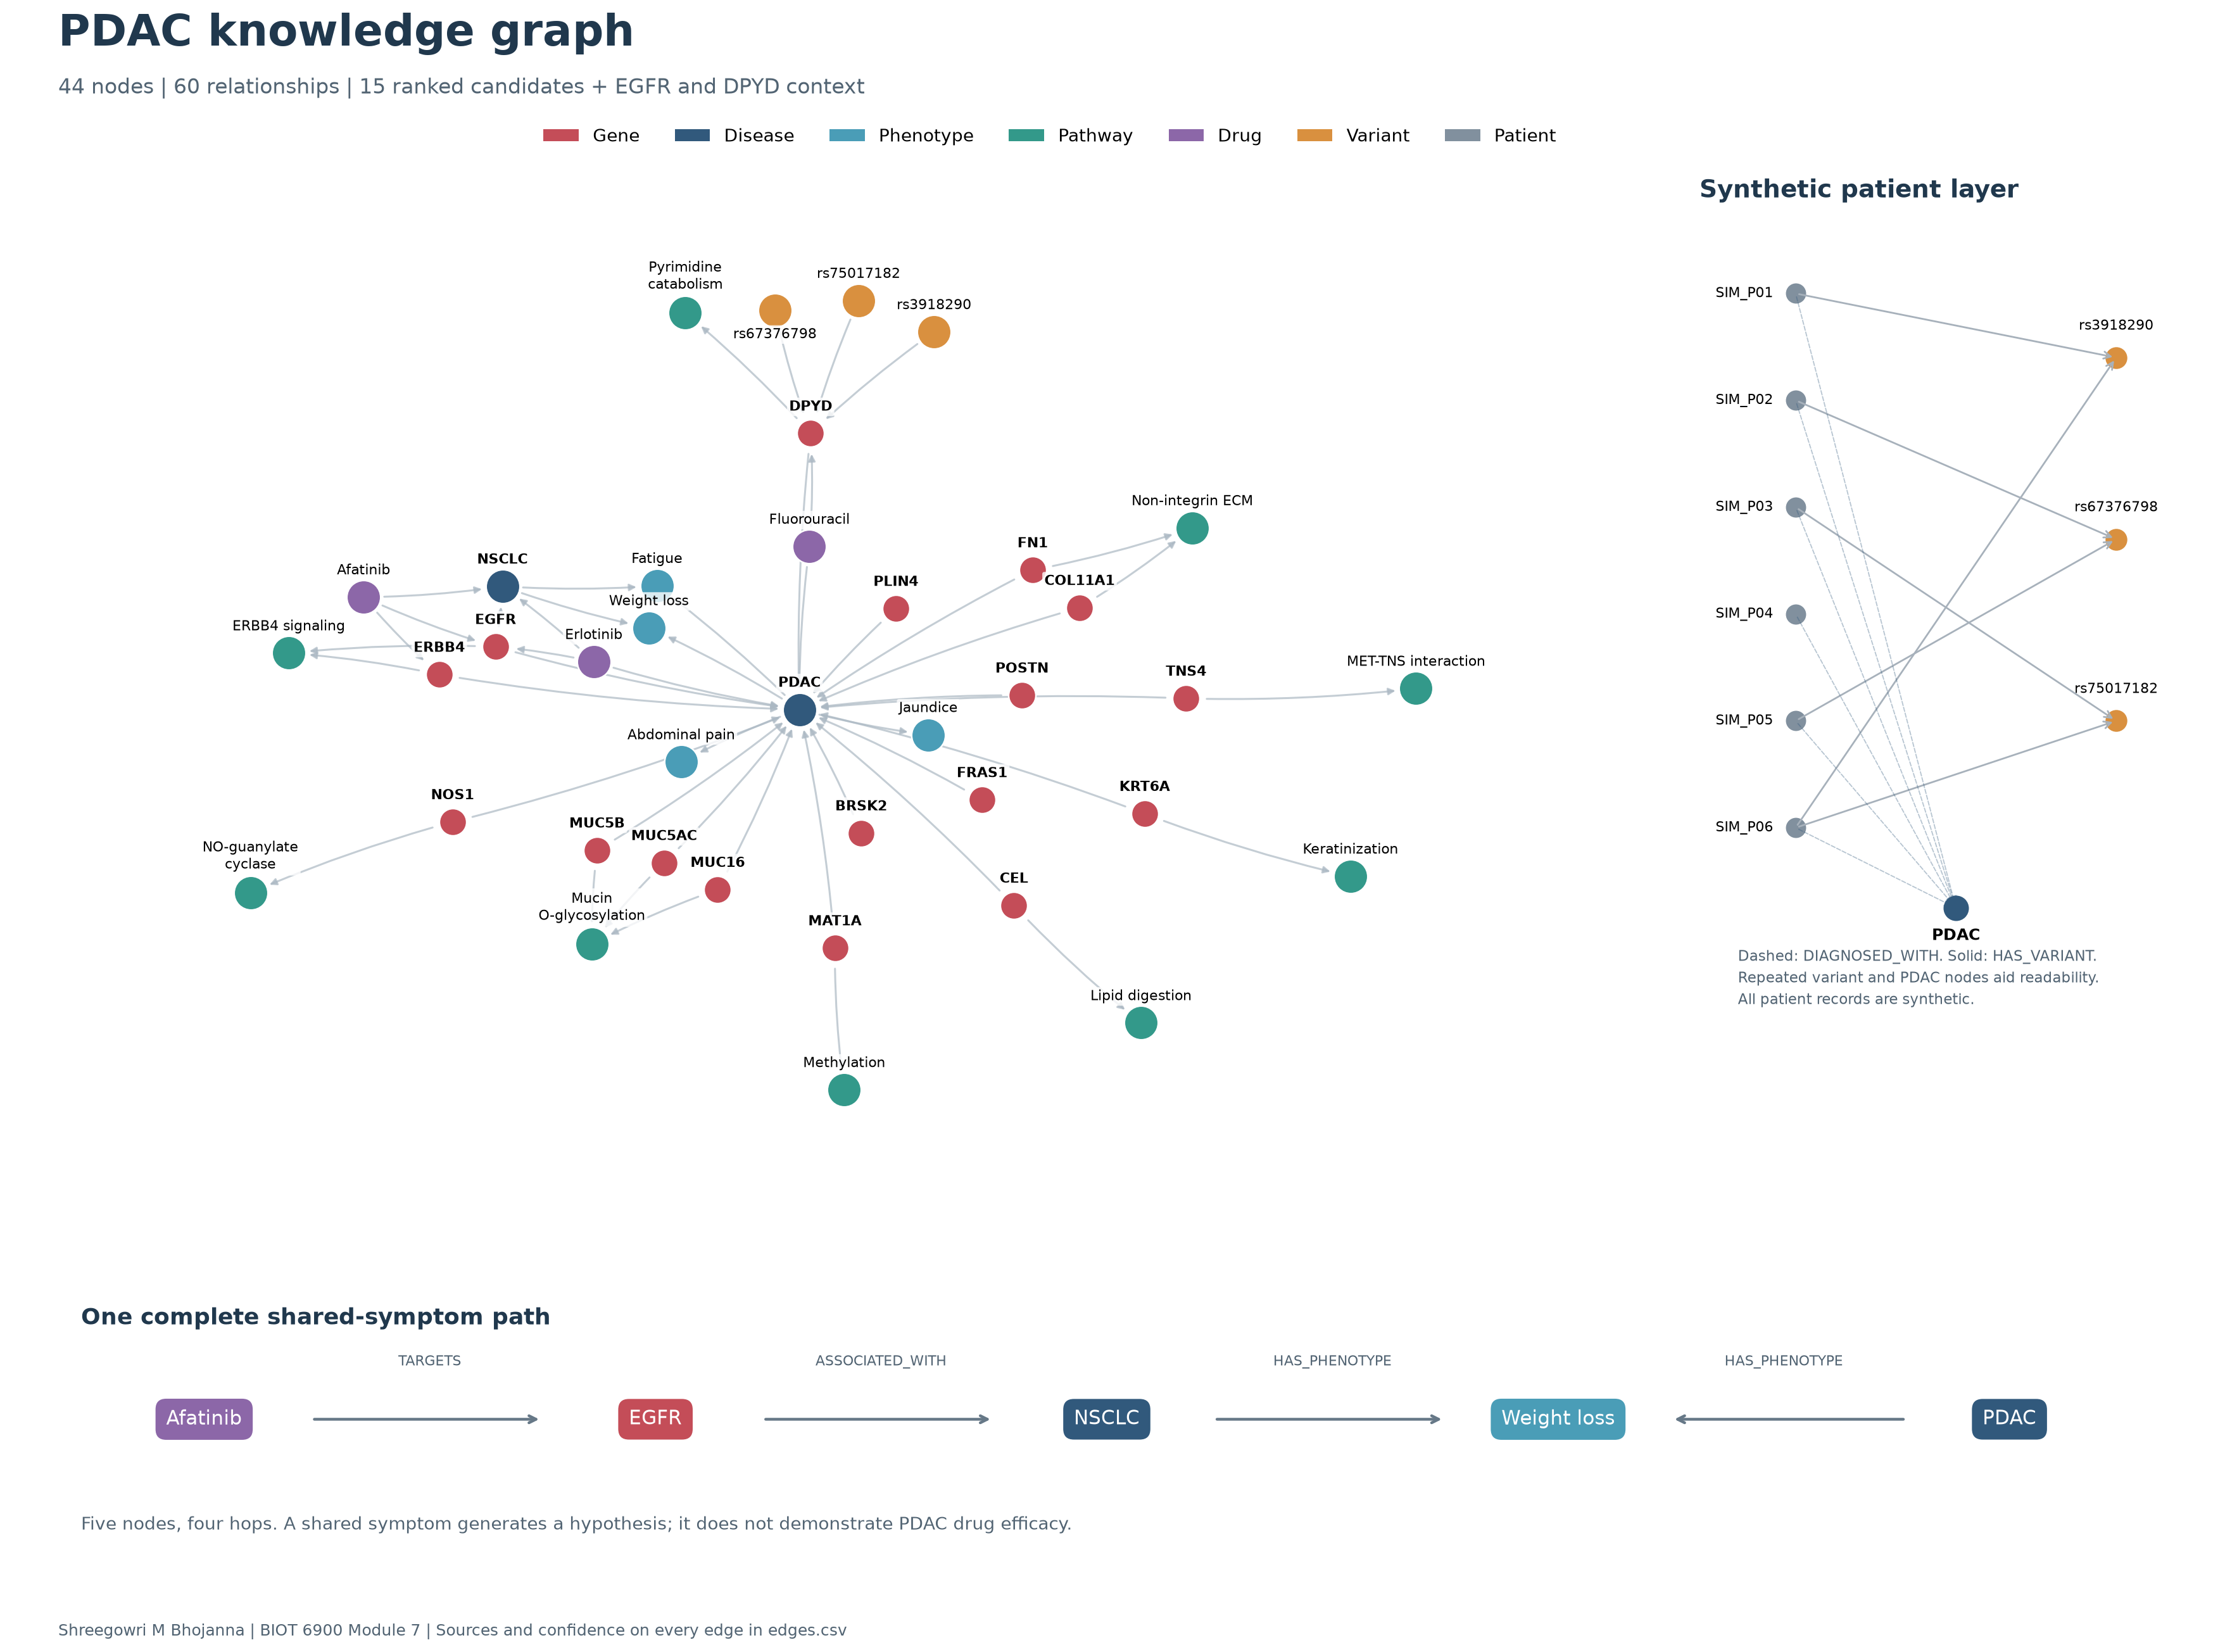

Saved my_knowledge_graph.png, nodes.csv, edges.csv and results/*.csv / *.json.


In [60]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyArrowPatch
import textwrap
COLORS={'gene':'#C44D58','disease':'#31597C','phenotype':'#4A9DB7','pathway':'#33998A','drug':'#8C67A8','variant':'#D9903F','patient':'#81909E'}
fig=plt.figure(figsize=(18,13.5),facecolor='white')
ax=fig.add_axes([0.025,0.25,0.72,0.65]); ax.set_axis_off()
pos=nx.spring_layout(G,seed=23,k=1.1,iterations=500,weight='weight')
draw_graph=nx.DiGraph();draw_graph.add_nodes_from(sorted(BIO));draw_graph.add_edges_from((e['src'],e['dst']) for e in BIO_EDGES)
nx.draw_networkx_edges(draw_graph,pos,ax=ax,edge_color='#ABB8C3',alpha=0.7,width=1.1,arrows=True,arrowsize=8,node_size=550,connectionstyle='arc3,rad=0.035')
for kind in ['gene','disease','phenotype','pathway','drug','variant']:
    nodes=[n for n in draw_graph if DB_NODES[n]['kind']==kind]
    nx.draw_networkx_nodes(draw_graph,pos,ax=ax,nodelist=nodes,node_color=COLORS[kind],node_size=240 if kind=='gene' else 370,edgecolors='white',linewidths=0.9)
short={DISEASE_ID:'PDAC',RELATED_ID:'NSCLC','R-HSA-913709':'Mucin O-glycosylation','R-HSA-3000171':'Non-integrin ECM','R-HSA-1236394':'ERBB4 signaling','R-HSA-8875513':'MET-TNS interaction','R-HSA-6805567':'Keratinization','R-HSA-156581':'Methylation','R-HSA-392154':'NO-guanylate cyclase','R-HSA-73621':'Pyrimidine catabolism','R-HSA-192456':'Lipid digestion'}
for nid,(x,y) in pos.items():
    label=short.get(nid,DB_NODES[nid]['name'])
    offset=(0,-18) if DB_NODES[nid]['name']=='rs67376798' else (0,11)
    ax.annotate('\n'.join(textwrap.wrap(label,19)),(x,y),xytext=offset,textcoords='offset points',ha='center',va='bottom',fontsize=8.1,fontweight='bold' if DB_NODES[nid]['kind'] in ('gene','disease') else 'normal',bbox=dict(boxstyle='round,pad=0.15',fc='white',ec='none',alpha=0.80))
ax.margins(0.14)
fig.text(0.045,0.955,'PDAC knowledge graph',fontsize=25,fontweight='bold',color='#20384D')
fig.text(0.045,0.927,f'{len(DB_NODES)} nodes | {len(DB_EDGES)} relationships | 15 ranked candidates + EGFR and DPYD context',fontsize=12,color='#526473')
fig.legend(handles=[Patch(facecolor=COLORS[k],label=k.capitalize()) for k in COLORS],loc='upper center',bbox_to_anchor=(0.48,0.916),ncol=7,frameon=False,fontsize=10)

ap=fig.add_axes([0.765,0.36,0.225,0.50]);ap.set_axis_off();ap.set_xlim(-0.3,1.30);ap.set_ylim(-2.2,5.8)
ap.set_title('Synthetic patient layer',loc='left',fontsize=14,fontweight='bold',color='#20384D')
var_ids=['GRCh38:'+a for a in EXACT_ALLELES]
vpos={n:(1,4.4-i*1.7) for i,n in enumerate(var_ids)}
ppos={'SYNTHETIC:'+p:(0,5-i) for i,(p,_) in enumerate(PATIENTS)}
for e in DB_EDGES:
    if e['rel']=='HAS_VARIANT':
        ap.annotate('',xy=vpos[e['dst']],xytext=ppos[e['src']],arrowprops=dict(arrowstyle='->',color='#A7B1BB',lw=1))
for nid,(x,y) in ppos.items():
    ap.annotate('',xy=(0.5,-0.75),xytext=(x,y),arrowprops=dict(arrowstyle='->',color='#31597C',lw=0.65,alpha=0.35,linestyle='dashed'))
    ap.scatter([x],[y],s=110,c=COLORS['patient']);ap.text(x-0.07,y,DB_NODES[nid]['name'],ha='right',va='center',fontsize=8)
for nid,(x,y) in vpos.items():
    ap.scatter([x],[y],s=130,c=COLORS['variant']);ap.text(x,y+0.23,DB_NODES[nid]['name'],ha='center',va='bottom',fontsize=8)
ap.scatter([0.5],[-0.75],s=180,c=COLORS['disease']);ap.text(0.5,-1.05,'PDAC',ha='center',fontsize=9,fontweight='bold')
ap.text(-0.18,-1.65,'Dashed: DIAGNOSED_WITH. Solid: HAS_VARIANT.\nRepeated variant and PDAC nodes aid readability.\nAll patient records are synthetic.',fontsize=8.2,color='#526473',linespacing=1.5)

at=fig.add_axes([0.055,0.06,0.90,0.15]);at.set_axis_off()
at.text(0,0.98,'One complete shared-symptom path',fontsize=13,fontweight='bold',color='#20384D')
labels=['Afatinib','EGFR','NSCLC','Weight loss','PDAC'];kinds=['drug','gene','disease','phenotype','disease']
xs=[0.06,0.28,0.50,0.72,0.94]
for x,label,kind in zip(xs,labels,kinds):
    at.text(x,0.61,label,ha='center',va='center',fontsize=11,color='white',bbox=dict(boxstyle='round,pad=0.55',fc=COLORS[kind],ec='none'))
for i,label in enumerate(['TARGETS','ASSOCIATED_WITH','HAS_PHENOTYPE','HAS_PHENOTYPE']):
    start,end=(xs[i]+0.052,xs[i+1]-0.055) if i<3 else (xs[i+1]-0.05,xs[i]+0.055)
    at.annotate('',xy=(end,0.61),xytext=(start,0.61),arrowprops=dict(arrowstyle='->',color='#667887',lw=1.6))
    at.text((xs[i]+xs[i+1])/2,0.82,label,ha='center',fontsize=7.8,color='#526473')
at.text(0,0.18,'Five nodes, four hops. A shared symptom generates a hypothesis; it does not demonstrate PDAC drug efficacy.',fontsize=10,color='#526473')
fig.text(0.045,0.025,'Shreegowri M Bhojanna | BIOT 6900 Module 7 | Sources and confidence on every edge in edges.csv',fontsize=9,color='#526473')
fig.savefig(BASE/'my_knowledge_graph.png',dpi=200,bbox_inches='tight',facecolor='white')
plt.close(fig)
from IPython.display import Image
display(Image(filename=str(BASE/'my_knowledge_graph.png'),width=1150))

node_table=pd.DataFrame(DB_NODES.values()).sort_values(['kind','name'])
node_table['gwas_p']=np.nan
node_table.to_csv(BASE/'nodes.csv',index=False)
pd.DataFrame(DB_EDGES).sort_values(['rel','src','dst']).to_csv(BASE/'edges.csv',index=False)
summary={'disease':DISEASE,'nodes':len(DB_NODES),'relationships':len(DB_EDGES),'node_counts':dict(Counter(d['kind'] for d in DB_NODES.values())),
 'biological_nodes':len(BIO),'biological_relationships':len(BIO_EDGES),'communities':len(communities),'modularity':q,
 'opening_rows':len(opening),'full_paths':len(paths),'synthetic_patients':len(strata),'candidate_genes':15,
 'top_fused':biomarkers[['gene','fused_score','pagerank']].head(5).to_dict('records'),
 'mucin_community':mucin_community,'server':driver.get_server_info().agent,
 'connection_scope':'local validation' if '127.0.0.1' in uri or 'localhost' in uri else 'configured instance'}
(RESULTS/'analysis_summary.json').write_text(json.dumps(summary,indent=2))
hashes={str(p.relative_to(BASE)):hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(DATA.glob('*')) if p.is_file()}
(RESULTS/'input_sha256.json').write_text(json.dumps(hashes,indent=2))
print('Saved my_knowledge_graph.png, nodes.csv, edges.csv and results/*.csv / *.json.')

## 8 - My interpretation and submission
The four-page report `module7_pdac_report.pdf` answers the four Part F questions.

**What I would keep in mind.** The graph makes the evidence traceable, but it does not improve the validity of the original evidence by connecting it. Bulk RNA/protein differences can reflect tumor purity, stroma or loss of normal pancreatic tissue. Absolute-effect ranking also promotes downregulated genes, so a high rank does not imply that inhibition is appropriate. The RNA/protein discordance for ERBB4 needs biological follow-up.

**Hypothesis to test.** Afatinib could be a useful experimental probe in an ERBB-dependent subset of PDAC models. I would measure ERBB4 and EGFR protein/phosphorylation, use independent gene perturbations with rescue, and compare those effects with drug response in PDAC organoids and appropriate controls. Concordant target engagement and a target-dependent effect would support the mechanism; drug cytotoxicity alone would not identify which ERBB target mattered. Shared fatigue or weight loss is not a selection biomarker.

**Weak edges and better data.** Shared symptoms have low specificity; the selected pathway set and well-annotated drugs bias centrality; gene-level mutation frequencies do not identify the driver allele; Module 3 priors are predictions; the Module 5 catalogue is an older annotation snapshot and contains condition-dependent ClinVar labels. Better matched patient-level tumor data, cell-type resolved expression, allele-specific functional results and independent clinical outcomes could change both the graph and its ranking. No synthetic patient fraction is interpreted as prevalence.

**AI use:** AI assistance used for coding, Cypher adaptation and drafting. 

### Sources
1. My Module 2 target CSV and preparation/ranking notebooks: CPTAC-PDAC, [LinkedOmics downloads](https://linkedomics.org/data_download/CPTAC-PDAC/). The earlier code defines effects as tumor mean minus normal mean and the genomic measure as mutation frequency.
2. My Module 3 `targets_pdac_w3.csv`: supplied `p_sm`, `p_ab`, original final score and rank; priors were carried forward without refitting or treating them as experimental pharmacology.
3. My Module 5 `DPYD.tsv`: 426 records; download 22 October 2026; MyVariant index 20250624. Exact genomic HGVS keys and condition-level ClinVar summaries are retained.
4. [HGNC REST](https://rest.genenames.org/) and [reviewed UniProt](https://rest.uniprot.org/), retrieved 30 October 2026. Per-gene URLs, version metadata and selected cross-references are in `data/annotation_snapshot.json`.
5. [Reactome](https://reactome.org/), via explicit reviewed UniProt cross-references. Each pathway ID and URL is in `data/pathway_memberships.csv`.
6. [Human Phenotype Ontology](https://github.com/obophenotype/human-phenotype-ontology), term IDs checked against the downloaded OBO; version/hash in `data/hpo_terms.json`.
7. [NCI pancreatic cancer PDQ](https://www.cancer.gov/types/pancreatic/hp/pancreatic-treatment-pdq) and [NCI NSCLC PDQ](https://www.cancer.gov/types/lung/patient/non-small-cell-lung-treatment-pdq), accessed 30 October 2026; symptom descriptions and treatment context.
8. [FDA GILOTRIF label, 2022](https://www.accessdata.fda.gov/drugsatfda_docs/label/2022/201292s017lbl.pdf), sections 1 and 12.1. Archived label establishes afatinib target and indication evidence; no claim that it is the newest label.
9. [FDA TARCEVA label, 2016](https://www.accessdata.fda.gov/drugsatfda_docs/label/2016/021743s025lbl.pdf), sections 1 and 12.1. Archived label establishes erlotinib target and disease context.
10. Amstutz et al. CPIC fluoropyrimidine-DPYD guideline, 2017 update. [doi:10.1002/cpt.911](https://doi.org/10.1002/cpt.911). Used for pharmacogenomic context, not to prescribe doses.
11. [UniProt DPYD Q12882](https://www.uniprot.org/uniprotkb/Q12882/entry), reviewed function: pyrimidine and fluorouracil metabolism.


In [61]:
# Final consistency checks and cleanup.
assert len(pd.read_csv(BASE/'nodes.csv'))==len(DB_NODES)
assert len(pd.read_csv(BASE/'edges.csv'))==len(DB_EDGES)
assert len(pd.read_csv(RESULTS/'candidate_biomarkers.csv'))==15
assert pd.read_csv(BASE/'edges.csv')[['source','source_url','confidence','evidence_type','evidence_note']].notna().all().all()
assert (BASE/'my_knowledge_graph.png').stat().st_size>10000
driver.close()
print('All checks passed. Database connection closed.')

All checks passed. Database connection closed.
